# 06 · Contratos de datos y SQL Athena

**Estado:** inventario y consultas orientativas, sin conexión ejecutada. Los CSV `plantilla_*.csv` tienen encabezados y no contienen observaciones. No se deben ejecutar las plantillas SQL hasta confirmar catálogo, permisos, semántica y costos con el responsable de datos.

**Objetivo:** especificar las tablas y controles mínimos para construir el backtesting de onboarding y las vistas point-in-time para análisis posteriores.

## 1 · Contratos y llaves

| Objeto | Grano | Campos mínimos | Reglas |
|---|---|---|---|
| Originación | cuenta u operación | `id_credito`, `id_comercio`, `id_cliente`, originación, estrategia, tipo, canal | una fila por llave; conservar fecha de disponibilidad |
| Panel mensual | cuenta y corte | llave, `fecha_corte`, `mob`, `dias_mora`, saldos, estado | un solo registro por cuenta–corte; investigar meses faltantes |
| Buró | consulta/cliente | score, proveedor, consulta, disponibilidad | corte as-of a la decisión; sin usar consultas futuras |
| Avances | transacción | `id_avance`, cuenta, importe, fecha efectiva y disponibilidad, estado | deduplicar y excluir reversos según reglas aprobadas |
| Geografía | cliente o catálogo vigente | municipio/departamento, vigencia y disponibilidad | no atribuir información futura ni exponer grupos pequeños |

No se asume que nombres de ejemplo coincidan con columnas físicas. El indicador de cuenta no es automáticamente indicador de cliente; para cliente se requiere una regla aprobada de múltiples tarjetas.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path.cwd()
if not (BASE/'plantilla_panel_mensual.csv').exists():
    BASE = next(p for p in [BASE, *BASE.parents] if (p/'03-financial-risk').is_dir()) / '03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab'
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
                     'font.size': 10, 'axes.titleweight': 'bold'})
print('Carpeta del laboratorio:', BASE.name)


Carpeta del laboratorio: credit-vintage-snapshot-lab


## Mapa de procedencia del resultado

Esquema conceptual de integración. No prueba que las fuentes, sus llaves o la disponibilidad existan en Athena.

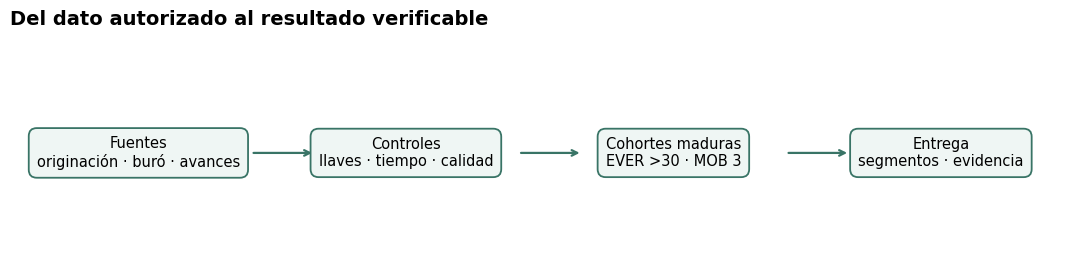

In [2]:
fig, ax = plt.subplots(figsize=(11, 2.8)); ax.axis('off')
labels=['Fuentes\noriginación · buró · avances','Controles\nllaves · tiempo · calidad','Cohortes maduras\nEVER >30 · MOB 3','Entrega\nsegmentos · evidencia']
for i,label in enumerate(labels):
    x=.12+i*.25
    ax.text(x,.5,label,transform=ax.transAxes,ha='center',va='center',fontsize=10.5,
            bbox=dict(boxstyle='round,pad=.55',fc='#eff6f4',ec='#397466',lw=1.3))
    if i<3:ax.annotate('',xy=(x+.165,.5),xytext=(x+.105,.5),xycoords='axes fraction',arrowprops=dict(arrowstyle='->',color='#397466',lw=1.6))
ax.set_title('Del dato autorizado al resultado verificable',loc='left',fontsize=14,pad=15)
plt.tight_layout();plt.show()

## 2 · Inspección del diccionario y contratos

El inventario señala fuentes candidatas, no una certificación de que las tablas existan o tengan permisos. Revisar tipos, unidad, propietario, retención y fechas de consulta antes de ingerir.

In [3]:
for name in ['inventario_fuentes.csv','diccionario_variables.csv','contratos_metricas.csv']:
    path=BASE/name; table=pd.read_csv(path)
    print(f'{name}: {len(table)} definiciones')
    display(table.head(8))

inventario_fuentes.csv: 16 definiciones


,dominio,tabla_candidata,catalogo_esquema,granularidad,clave_primaria,fecha_evento,fecha_disponibilidad,confirmada,observaciones
0,creditos_originacion,NaN,NaN,NaN,NaN,NaN,NaN,NO,Pendiente de inventario Athena
1,panel_mensual,NaN,NaN,NaN,NaN,NaN,NaN,NO,Pendiente de inventario Athena
2,clientes,NaN,NaN,NaN,NaN,NaN,NaN,NO,Pendiente de inventario Athena
3,comercios,NaN,NaN,NaN,NaN,NaN,NaN,NO,Pendiente de inventario Athena
4,transacciones,NaN,NaN,NaN,NaN,NaN,NaN,NO,Pendiente de inventario Athena
5,buro,NaN,NaN,NaN,NaN,NaN,NaN,NO,Pendiente de inventario Athena
6,avances_tarjeta,NaN,NaN,NaN,NaN,NaN,NaN,NO,Pendiente de inventario Athena
7,geografia_contexto,NaN,NaN,NaN,NaN,NaN,NaN,NO,Pendiente de inventario Athena


diccionario_variables.csv: 226 definiciones


,dataset,campo,definicion_negocio,estado_fuente,tabla_origen_real,tipo_dato_confirmado,clave_join,observaciones
0,creditos_originacion,id_credito,NaN,derivable de SQL compartido; verificar semántica,NaN,No confirmado,NaN,NaN
1,creditos_originacion,id_comercio,NaN,derivable de SQL compartido; verificar semántica,NaN,No confirmado,NaN,NaN
2,creditos_originacion,id_cliente,NaN,derivable de SQL compartido; verificar semántica,NaN,No confirmado,NaN,NaN
3,creditos_originacion,referencia_credito,NaN,derivable de SQL compartido; verificar semántica,NaN,No confirmado,NaN,NaN
4,creditos_originacion,fecha_solicitud,NaN,derivable de SQL compartido; verificar semántica,NaN,No confirmado,NaN,NaN
5,creditos_originacion,fecha_desembolso,NaN,derivable de SQL compartido; verificar semántica,NaN,No confirmado,NaN,NaN
6,creditos_originacion,corte_origen,NaN,derivable de SQL compartido; verificar semántica,NaN,No confirmado,NaN,NaN
7,creditos_originacion,tipo_cliente,NaN,derivable de SQL compartido; verificar semántica,NaN,No confirmado,NaN,NaN


contratos_metricas.csv: 13 definiciones


,metrica,unidad,numerador,denominador,ventana,umbral_dpd,regla_maduracion,observaciones
0,EVER_MOB3_CUENTAS,cuentas,cuentas maduras con max(DPD)>30 en MOB 1..3,"cuentas con MOB 1,2,3 y DPD observado",MOB 1-3,>30,"MOB 1,2,3 completos",MOB 0 opcional; episodios intrames pueden no o...
1,EVER_MOB3_CLIENTES,clientes,clientes maduros con alguna cuenta representad...,clientes con todas sus cuentas representadas m...,MOB 1-3,>30,todas las cuentas representadas completas,no identifica cuentas ausentes del extracto
2,EVER_MOB3_SALDO,COP,saldo capital MOB3 de cuentas maduras con EVER...,saldo capital MOB3 de cuentas maduras con sald...,MOB 1-3,>30,"MOB 1,2,3 completos",saldo no nulo y no negativo; no es pérdida; co...
3,OVER30_CUENTAS,cuentas,cuentas con DPD>30 al corte,cuentas con DPD observado al corte,corte mensual,>30,no aplica,fotografía; no equivale a EVER
4,OVER30_SALDO,COP,saldo de cuentas con DPD>30 al corte,saldo válido al corte,corte mensual,>30,no aplica,"definir castigos, saldos inválidos y población"
5,PUENTE_CASTIGO_DADO_EVER,cuentas,cuentas maduras con EVER>30@MOB3 castigadas ha...,cuentas maduras con EVER>30@MOB3 y seguimiento...,MOB 1-18,>30,cohorte con MOB 18 observado,re-estimar por cohorte; cancelaciones como eve...
6,CASTIGO_PROYECTADO,cuentas,r·P(C|E)+(1−r)·P(C|¬E),no aplica,MOB 18,>30,puente vigente,hereda el supuesto de estabilidad del puente
7,MARGEN_AJUSTADO_RIESGO,COP por cuenta y año,ingreso − costo − PD·LGD·EAD,no aplica,anual,no aplica,no aplica,cifras aprobadas por Finanzas


## 3 · Descubrimiento de tablas y columnas

Consulta de metadatos de ejemplo; se imprime, **no se envía** a Athena. Ajustar catálogo/esquema con el dueño. El resultado debe verificarse contra diccionario, granularidad, zona horaria y fecha de disponibilidad.

In [4]:
sql_discovery = """-- Athena / información de metadatos: adaptar catálogo y esquema autorizados
SELECT table_schema, table_name, column_name, data_type
FROM information_schema.columns
WHERE lower(table_schema) = '<esquema_autorizado>'
  AND regexp_like(lower(column_name), 'credito|cuenta|cliente|comercio|score|avance|transaccion|fecha|mora')
ORDER BY table_name, ordinal_position
"""
print(sql_discovery)

-- Athena / información de metadatos: adaptar catálogo y esquema autorizados
SELECT table_schema, table_name, column_name, data_type
FROM information_schema.columns
WHERE lower(table_schema) = '<esquema_autorizado>'
  AND regexp_like(lower(column_name), 'credito|cuenta|cliente|comercio|score|avance|transaccion|fecha|mora')
ORDER BY table_name, ordinal_position



## 4 · Anclaje temporal del score: consulta conceptual

Para una cuenta y decisión $t_i$, seleccionar la última consulta de buró cuyo evento **y disponibilidad** sean $\le t_i$. En empates, definir una clave estable y prioridad por proveedor; los identificadores deben resolverse antes del join. El ejemplo usa `<...>` como marcadores; no supone datos de AWS existentes. Cuidar nulos: una ausencia de score no es score cero.

In [5]:
sql_buro = """-- SOLO DISEÑO. Sustituir tablas, tipos y particiones validadas.
WITH candidatos AS (
  SELECT o.id_credito, o.id_comercio, o.id_cliente, o.fecha_decision,
         b.score_buro, b.fecha_consulta, b.fecha_disponibilidad,
         row_number() OVER (
           PARTITION BY o.id_credito, o.id_comercio
           ORDER BY b.fecha_disponibilidad DESC, b.fecha_consulta DESC, b.consulta_id DESC
         ) AS rn
  FROM <originaciones_validadas> o
  LEFT JOIN <consultas_buro_validadas> b
    ON o.id_cliente=b.id_cliente
   AND b.fecha_consulta <= o.fecha_decision
   AND b.fecha_disponibilidad <= o.fecha_decision
)
SELECT * FROM candidatos WHERE rn=1
"""
print(sql_buro)

-- SOLO DISEÑO. Sustituir tablas, tipos y particiones validadas.
WITH candidatos AS (
  SELECT o.id_credito, o.id_comercio, o.id_cliente, o.fecha_decision,
         b.score_buro, b.fecha_consulta, b.fecha_disponibilidad,
         row_number() OVER (
           PARTITION BY o.id_credito, o.id_comercio
           ORDER BY b.fecha_disponibilidad DESC, b.fecha_consulta DESC, b.consulta_id DESC
         ) AS rn
  FROM <originaciones_validadas> o
  LEFT JOIN <consultas_buro_validadas> b
    ON o.id_cliente=b.id_cliente
   AND b.fecha_consulta <= o.fecha_decision
   AND b.fecha_disponibilidad <= o.fecha_decision
)
SELECT * FROM candidatos WHERE rn=1



## 5 · Avances al corte y comparabilidad

$A_i(t)=\sum_j m_{ij}\mathbf 1(f_{ij}\le t, a_{ij}\le t, e_{ij}=\text{válido})$, donde $f$ es fecha efectiva y $a$ disponibilidad. Derivar MOB con el **mismo calendario de originación** de la tabla de cohortes; no convertir `days/30` en MOB sin contrato. Confirmar reversos, moneda, cupo, titular y cuentas adicionales.

El siguiente esquema conceptual protege el punto en el tiempo; el filtro por estado y los joins son marcadores de negocio que deben aprobarse. No agrupar por cliente si el objetivo aprobado es por cuenta.

La plantilla de avances no incluye `id_comercio`. El join mostrado requiere demostrar que `id_credito` es globalmente única; si no lo es, incorporar la llave compuesta o una tabla puente validada antes de agregar. `estado_valido_aprobado` y `consulta_id` son nombres hipotéticos que requieren mapeo.

In [6]:
sql_avances = """-- SOLO DISEÑO. No ejecutar hasta verificar llaves y fecha de disponibilidad.
SELECT o.id_credito, o.id_comercio, o.fecha_decision,
       count(a.id_avance) AS numero_avances_observados,
       sum(a.monto_avance_cop) AS monto_avance_observado_cop
FROM <cuentas_y_decision_validadas> o
LEFT JOIN <avances_validados> a
  ON a.id_credito=o.id_credito
 AND a.fecha_avance <= o.fecha_decision
 AND a.fecha_disponibilidad <= o.fecha_decision
 AND a.estado = '<estado_valido_aprobado>'
GROUP BY 1,2,3
-- Un SUM nulo puede significar falta de fuente: no convertir a cero sin control de cobertura.
"""
print(sql_avances)

-- SOLO DISEÑO. No ejecutar hasta verificar llaves y fecha de disponibilidad.
SELECT o.id_credito, o.id_comercio, o.fecha_decision,
       count(a.id_avance) AS numero_avances_observados,
       sum(a.monto_avance_cop) AS monto_avance_observado_cop
FROM <cuentas_y_decision_validadas> o
LEFT JOIN <avances_validados> a
  ON a.id_credito=o.id_credito
 AND a.fecha_avance <= o.fecha_decision
 AND a.fecha_disponibilidad <= o.fecha_decision
 AND a.estado = '<estado_valido_aprobado>'
GROUP BY 1,2,3
-- Un SUM nulo puede significar falta de fuente: no convertir a cero sin control de cobertura.



## 6 · Definición de EVER y maduración

Para un conjunto de MOB acordado $W=\{1,2,3\}$, $Y_i=\max_{m\in W}\mathbf1(DPD_{i,m}>30)$. La cuenta es elegible para tasa de MOB 3 solo cuando el seguimiento requerido de $W$ es observable y las reglas de salida/castigo están aprobadas. Un registro en MOB 3 por sí solo **no** garantiza que se observaron MOB 1 y 2. Si se adopta MOB 0 o ≥30, cambiar contrato, código y documentación juntos. La mora entre cortes mensuales solo se identifica si la fuente trae máximo entre cortes; un snapshot de fin de mes puede pasar por alto episodios intermedios.

Para monto: $EVER^{\$}=\sum_{i\in E}B_iY_i/\sum_{i\in E}B_i$, donde $B_i$ debe ser saldo en originación, primer evento o MOB 3 **por decisión explícita**, con denominador positivo. Saldo en EVER no es pérdida: recuperación, castigo y contabilidad se modelan por separado. El motor aprobado debe aplicar reglas de cierre, saldo cero, duplicados y fechas de disponibilidad al mismo tiempo.

## 7 · Controles de entrega y señales de rechazo

1. Reportar filas, llaves nulas y duplicadas por tabla; ninguna tabla debe expandir el grano accidentalmente en un join.
2. Reconciliar saldo total y capital por corte y cohorte contra el sistema contable; no asumir que el total son sumas equivalentes.
3. Medir cobertura de score, ubicación, estrategia y avances; registrar cuándo faltante significa desconocido y cuándo se puede confirmar cero.
4. Verificar secuencia de fechas, MOB válidos y cobertura requerida, incluyendo cierres y castigos.
5. Congelar fuentes, diccionario, consulta, ventana, parámetros y hash; usar agregados para reportes y controles de acceso a microdatos.
6. Validar el resultado contra recuentos independientes y revisar tramos pequeños con gobierno de datos.

Una falla bloquea la entrega del indicador correspondiente; no la convierte en una tasa de cero.

In [7]:
checks = pd.DataFrame([
    ('Llave cuenta–corte', 'Sin nulos ni duplicados', 'Bloqueante'),
    ('Ventana MOB 1–3', 'Meses requeridos observados o regla de salida aprobada', 'Bloqueante'),
    ('Disponibilidad de predictores', 'No posterior a decisión', 'Bloqueante'),
    ('Saldo y definición EVER $', 'Saldo fechado, denominador positivo y reconciliación', 'Bloqueante'),
    ('Score, ubicación y avances', 'Cobertura y ausencias documentadas', 'Revisión'),
    ('Muestra y exposición por segmento', 'Umbral de privacidad y denominadores publicados', 'Revisión')],
    columns=['Control','Criterio','Acción'])
display(checks)

,Control,Criterio,Acción
0,Llave cuenta–corte,Sin nulos ni duplicados,Bloqueante
1,Ventana MOB 1–3,Meses requeridos observados o regla de salida ...,Bloqueante
2,Disponibilidad de predictores,No posterior a decisión,Bloqueante
3,Saldo y definición EVER $,"Saldo fechado, denominador positivo y reconcil...",Bloqueante
4,"Score, ubicación y avances",Cobertura y ausencias documentadas,Revisión
5,Muestra y exposición por segmento,Umbral de privacidad y denominadores publicados,Revisión


## 7b · Fuentes para las preguntas de decisión (notebooks 07–11)

| Objeto | Grano | Campos mínimos | Uso | Regla crítica |
|---|---|---|---|---|
| Desempeño largo | cuenta | castigo y MOB de castigo, saldo castigado, recuperaciones, pérdida neta, `seguimiento_largo_completo` | puente EVER → pérdida (07) | solo cohortes con MOB 18 observado al corte; cancelaciones como evento competitivo |
| Serie macro | mes calendario | desempleo, tasa de intervención, inflación, fecha de publicación | efecto período (07) | usar la serie disponible en la fecha, no la revisada |
| Solicitudes | solicitud | **aprobadas y rechazadas**, score, TPV, decisión, motivo, versión de política | swap set, inferencia de rechazados (09) | sin rechazados no se puede evaluar aflojar una política |
| Bureau retro | solicitud | malo en otras entidades a 12 meses, definición, ventana | validación de la inferencia (09) | acuerdo con el proveedor, base legal y definición de malo comparable |
| Economía por segmento | segmento y período | saldo, EAD, tasa, intercambio, comisiones, fondeo, operación, adquisición, LGD, capital | margen ajustado, PD de equilibrio, corte (08) | cifras aprobadas por Finanzas, con fecha y fuente |
| Versiones de política | regla y vigencia | `plantilla_politicas.csv`: fecha de inicio y fin, segmento, regla, umbral | DiD y lectura de cohortes (07, 10) | registrar **todo** cambio, también los de cupo de avance |
| Experimentos | experimento | hipótesis, brazos, sal, métrica, MDE, tamaño, detención | prueba controlada (11) | registrar antes de iniciar; no cambiar la métrica después |


In [8]:
sql_desempeno_largo = """-- SOLO DISEÑO. Castigo y pérdida a MOB 18 por cuenta; sustituir tablas y reglas de castigo aprobadas.
SELECT c.id_credito, c.id_comercio, c.corte_origen,
       date_add('month', 18, date_parse(c.corte_origen || '-01', '%Y-%m-%d')) <= DATE '<fecha_asof>' AS seguimiento_largo_completo,
       max(CASE WHEN p.castigado = 1 AND p.mob <= 18 THEN 1 ELSE 0 END)            AS castigo_largo,
       min(CASE WHEN p.castigado = 1 THEN p.mob END)                                AS mob_castigo,
       max(CASE WHEN p.castigado = 1 AND p.mob <= 18 THEN p.saldo_capital_cop END)  AS saldo_castigado_cop,
       coalesce(sum(r.monto_recuperado_cop), 0)                                     AS recuperaciones_cop
FROM <cohortes_validadas> c
JOIN <panel_mensual_validado> p ON p.id_credito = c.id_credito AND p.id_comercio = c.id_comercio
LEFT JOIN <recuperaciones_validadas> r
  ON r.id_credito = c.id_credito AND r.fecha_disponibilidad <= DATE '<fecha_asof>'
WHERE p.fecha_disponibilidad <= DATE '<fecha_asof>'
GROUP BY 1, 2, 3
-- Pérdida neta = saldo castigado − recuperaciones, con la regla de descuento que apruebe Finanzas.
"""
sql_solicitudes = """-- SOLO DISEÑO. Universo de solicitudes, incluidas las rechazadas, con la política vigente al decidir.
SELECT s.id_solicitud, s.id_cliente, s.id_comercio, s.fecha_solicitud,
       date_format(s.fecha_solicitud, '%Y-%m') AS corte_origen,
       s.estrategia_originacion, s.score_buro, s.tpv_mensual_cop, s.decision, s.motivo_rechazo,
       pol.id_politica AS version_politica, o.id_credito
FROM <solicitudes_validadas> s
LEFT JOIN <politicas_validadas> pol
  ON s.fecha_solicitud BETWEEN pol.fecha_inicio AND coalesce(pol.fecha_fin, DATE '9999-12-31')
 AND pol.estrategia_originacion = s.estrategia_originacion
LEFT JOIN <originaciones_validadas> o ON o.id_solicitud = s.id_solicitud
-- Control: cada solicitud debe tener exactamente una versión de política; cada aprobada, un crédito.
"""
print(sql_desempeno_largo); print(sql_solicitudes)


-- SOLO DISEÑO. Castigo y pérdida a MOB 18 por cuenta; sustituir tablas y reglas de castigo aprobadas.
SELECT c.id_credito, c.id_comercio, c.corte_origen,
       date_add('month', 18, date_parse(c.corte_origen || '-01', '%Y-%m-%d')) <= DATE '<fecha_asof>' AS seguimiento_largo_completo,
       max(CASE WHEN p.castigado = 1 AND p.mob <= 18 THEN 1 ELSE 0 END)            AS castigo_largo,
       min(CASE WHEN p.castigado = 1 THEN p.mob END)                                AS mob_castigo,
       max(CASE WHEN p.castigado = 1 AND p.mob <= 18 THEN p.saldo_capital_cop END)  AS saldo_castigado_cop,
       coalesce(sum(r.monto_recuperado_cop), 0)                                     AS recuperaciones_cop
FROM <cohortes_validadas> c
JOIN <panel_mensual_validado> p ON p.id_credito = c.id_credito AND p.id_comercio = c.id_comercio
LEFT JOIN <recuperaciones_validadas> r
  ON r.id_credito = c.id_credito AND r.fecha_disponibilidad <= DATE '<fecha_asof>'
WHERE p.fecha_disponibilidad <= DATE '<fecha_asof>'

In [9]:
nuevas = ['plantilla_desempeno_largo.csv', 'plantilla_macro_mensual.csv', 'plantilla_solicitudes.csv', 'plantilla_bureau_retro.csv',
          'plantilla_economia_segmento.csv', 'plantilla_experimentos.csv']
display(pd.DataFrame({'plantilla': nuevas, 'columnas': [len(pd.read_csv(BASE / n, encoding='utf-8-sig').columns) for n in nuevas],
                      'filas': [len(pd.read_csv(BASE / n, encoding='utf-8-sig')) for n in nuevas]}))
dic = pd.read_csv(BASE / 'diccionario_variables.csv', encoding='utf-8-sig')
for n in nuevas:
    ds = n.removeprefix('plantilla_').removesuffix('.csv')
    cols = set(pd.read_csv(BASE / n, encoding='utf-8-sig').columns)
    faltan = cols - set(dic.loc[dic.dataset == ds, 'campo'])
    assert not faltan, f'{n}: campos sin definición en el diccionario: {sorted(faltan)}'
print('Cada campo de las plantillas nuevas está definido en el diccionario.')


,plantilla,columnas,filas
0,plantilla_desempeno_largo.csv,14,0
1,plantilla_macro_mensual.csv,8,0
2,plantilla_solicitudes.csv,19,0
3,plantilla_bureau_retro.csv,9,0
4,plantilla_economia_segmento.csv,16,0
5,plantilla_experimentos.csv,17,0


Cada campo de las plantillas nuevas está definido en el diccionario.


## 8 · Dependencias y cierre

Las plantillas son encabezados y el SQL mostrado es orientativo. No hay consulta ejecutada ni evidencia de acceso a Athena en este notebook. Para habilitar el análisis se necesita exportación autorizada, validación de gobernanza y de los contratos por área de riesgo. El notebook 05 incluye una plantilla explícita para el caso de alerta al cierre de MOB 1 y valida disponibilidad antes de entrenar.